# Chapitre 2 - Cours 2 : théorie de la décision et fléau de la dimension

Ce notebook couvre les sections 2.4 et 2.5 du livre.

1. **Théorie de la décision statistique** : quelle est la meilleure prédiction possible
   lorsque l'on connaît la loi jointe de $(X, Y)$ ? Réponse : la **fonction de
   régression** $f(x) = E(Y \mid X = x)$ pour la perte quadratique, et le
   **classifieur de Bayes** pour la perte 0-1.
2. **Fléau de la dimension** : pourquoi les méthodes locales (comme les $k$-ppv), qui
   approchent bien $E(Y\mid X=x)$ en petite dimension, s'effondrent en grande dimension.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl.plotting import decision_grid
from esl import datasets
from esl import ch02_supervise as c2

set_style()
rng = np.random.RandomState(0)

## 1. Fonction de perte et erreur de prédiction espérée

Soit $X \in \mathbb R^p$ un vecteur aléatoire d'entrée et $Y \in \mathbb R$ une sortie
aléatoire, de loi jointe $\Pr(X, Y)$. On cherche une fonction $f$ telle que $f(X)$
prédise bien $Y$. Il faut d'abord dire ce que « bien » veut dire : on se donne une
**fonction de perte** $L(Y, f(X))$ qui pénalise les erreurs.

Le choix le plus courant est la **perte quadratique** $L(Y, f(X)) = (Y - f(X))^2$.
On juge alors $f$ par son **erreur de prédiction espérée** (*expected prediction error*)
$$\mathrm{EPE}(f) = E\big[(Y - f(X))^2\big] = \int (y - f(x))^2 \Pr(dx, dy) \qquad \text{(éq. (2.9)-(2.10) du livre)}.$$

**Conditionnement.** Rappelons la formule de l'espérance totale : pour toute variable
intégrable $Z$, $E[Z] = E_X\big[E(Z \mid X)\big]$. Appliquée à $Z = (Y - f(X))^2$ :
$$\mathrm{EPE}(f) = E_X\Big[E_{Y\mid X}\big([Y - f(X)]^2 \mid X\big)\Big] \qquad \text{(éq. (2.11))}.$$
Il suffit donc de minimiser **point par point** : pour chaque $x$, choisir la valeur
$c = f(x)$ qui minimise $E\big([Y - c]^2 \mid X = x\big)$ (éq. (2.12)).

**Minimisation en $c$.** Notons $m(x) = E(Y \mid X = x)$. On écrit $Y - c = (Y - m(x)) + (m(x) - c)$
et on développe le carré :
$$E\big[(Y - c)^2 \mid X = x\big] = E\big[(Y - m(x))^2 \mid X = x\big] + 2(m(x) - c)\,E\big[Y - m(x) \mid X = x\big] + (m(x) - c)^2.$$
Le terme croisé est nul car $E[Y - m(x) \mid X = x] = m(x) - m(x) = 0$. Il reste
$$E\big[(Y - c)^2 \mid X = x\big] = \mathrm{Var}(Y \mid X = x) + (m(x) - c)^2,$$
minimal pour $c = m(x)$.

On obtient la **fonction de régression**
$$f(x) = E(Y \mid X = x) \qquad \text{(éq. (2.13))}.$$

> **À retenir.** Pour la perte quadratique, la meilleure prédiction de $Y$ au point
> $X = x$ est la moyenne conditionnelle. L'erreur résiduelle minimale vaut
> $E_X[\mathrm{Var}(Y\mid X)]$ : c'est un bruit irréductible.

## 2. Deux façons d'approcher $E(Y \mid X = x)$

**Les $k$-ppv** approchent directement cette définition :
$$\hat f(x) = \mathrm{Ave}\big(y_i \mid x_i \in N_k(x)\big) \qquad \text{(éq. (2.14))}.$$
Deux approximations interviennent : l'espérance est remplacée par une moyenne
empirique, et le conditionnement « au point $x$ » par un conditionnement « dans un
voisinage de $x$ ». Si $N, k \to \infty$ avec $k/N \to 0$, on peut montrer que
$\hat f(x) \to E(Y \mid X = x)$ (sous des hypothèses de régularité).

Illustrons cette convergence en dimension 1 : $X \sim \mathcal U(0, 1)$,
$Y = \sin(2\pi X) + \varepsilon$ avec $\varepsilon \sim \mathcal N(0, 0{,}3^2)$, donc
$E(Y \mid X = x) = \sin(2\pi x)$. On prend $k \approx \sqrt N$, ce qui assure
$k \to \infty$ et $k/N \to 0$.

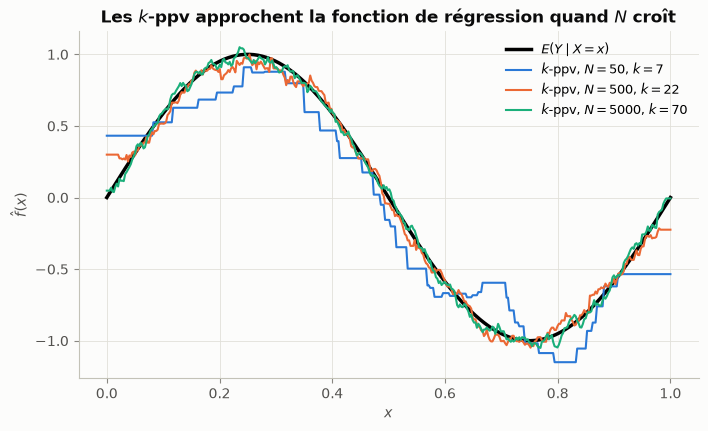

In [2]:
f_true = lambda x: np.sin(2 * np.pi * x)
x_plot = np.linspace(0, 1, 400)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(x_plot, f_true(x_plot), color="k", lw=2.5, label="$E(Y\\mid X=x)$")
for j, N in enumerate([50, 500, 5000]):
    x_tr = rng.uniform(size=N)
    y_tr = f_true(x_tr) + 0.3 * rng.normal(size=N)
    k = int(np.sqrt(N))
    ax.plot(x_plot, c2.knn_regress(x_tr, y_tr, x_plot, k), color=COLORS[j], lw=1.5,
            label="$k$-ppv, $N=%d$, $k=%d$" % (N, k))
ax.set_xlabel("$x$")
ax.set_ylabel("$\\hat f(x)$")
ax.set_title("Les $k$-ppv approchent la fonction de régression quand $N$ croît")
ax.legend()
plt.show()

**La régression linéaire** est une approche fondée sur un **modèle** : on suppose que
$f(x) \approx x^T\beta$ (éq. (2.15)). Injectons ce modèle dans l'EPE et minimisons
$\beta \mapsto E[(Y - X^T\beta)^2]$. Le gradient vaut $-2E[X(Y - X^T\beta)]$ (on dérive
sous l'espérance, par linéarité) ; il s'annule pour
$$\beta = \big[E(XX^T)\big]^{-1}E(XY) \qquad \text{(éq. (2.16))}.$$
La solution des moindres carrés (2.6) s'obtient en remplaçant ces espérances par des
moyennes empiriques : $\frac1N\mathbf X^T\mathbf X \approx E(XX^T)$ et
$\frac1N\mathbf X^T\mathbf y \approx E(XY)$.

Vérifions numériquement sur l'exemple sinusoïdal (avec la constante : $X = (1, x)$).
Pour $x \sim \mathcal U(0,1)$, on calcule à la main $E(XX^T) = \begin{pmatrix}1 & 1/2\\ 1/2 & 1/3\end{pmatrix}$,
$E(Y) = \int_0^1 \sin(2\pi x)\,dx = 0$ et $E(xY) = \int_0^1 x\sin(2\pi x)\,dx = -\frac{1}{2\pi}$
(intégration par parties).

In [3]:
EXX = np.array([[1, 0.5], [0.5, 1 / 3]])
EXY = np.array([0.0, -1 / (2 * np.pi)])
beta_pop = np.linalg.solve(EXX, EXY)
x_big = rng.uniform(size=200000)
y_big = f_true(x_big) + 0.3 * rng.normal(size=x_big.size)
print("beta population (2.16)    :", np.round(beta_pop, 4))
print("beta moindres carrés (2.6):", np.round(c2.least_squares_fit(x_big, y_big), 4))

beta population (2.16)    : [ 0.9549 -1.9099]
beta moindres carrés (2.6): [ 0.951 -1.905]


> **Remarque.** Les deux méthodes approchent l'espérance conditionnelle par des
> moyennes, mais avec des hypothèses très différentes : les moindres carrés supposent
> $f$ **globalement linéaire** ; les $k$-ppv supposent $f$ **localement constante**.
> Les modèles **additifs** $f(X) = \sum_j f_j(X_j)$ (éq. (2.17), chapitre 9) sont un
> intermédiaire.

## 3. Autre perte : la valeur absolue et la médiane

Avec la perte $L_1$, $L(Y, f(X)) = |Y - f(X)|$, le même raisonnement point par point
conduit à minimiser $c \mapsto E(|Y - c| \mid X = x)$. La solution est la **médiane
conditionnelle** (éq. (2.18)) :
$$\hat f(x) = \mathrm{médiane}(Y \mid X = x).$$

**Justification rapide.** Si $Y$ a une densité, notons $F$ sa fonction de répartition
(conditionnelle). On a $E|Y - c| = \int_{-\infty}^c (c - y)\,dF(y) + \int_c^{+\infty}(y - c)\,dF(y)$,
dont la dérivée en $c$ vaut $F(c) - (1 - F(c)) = 2F(c) - 1$ : elle s'annule pour
$F(c) = 1/2$, c'est-à-dire en la médiane.

Lorsque la loi conditionnelle est **asymétrique**, moyenne et médiane diffèrent.
Prenons $Y \mid X = x \sim \mathcal E(1)$ (loi exponentielle), de moyenne 1 et de
médiane $\ln 2 \approx 0{,}693$, et traçons les deux risques en fonction de $c$.

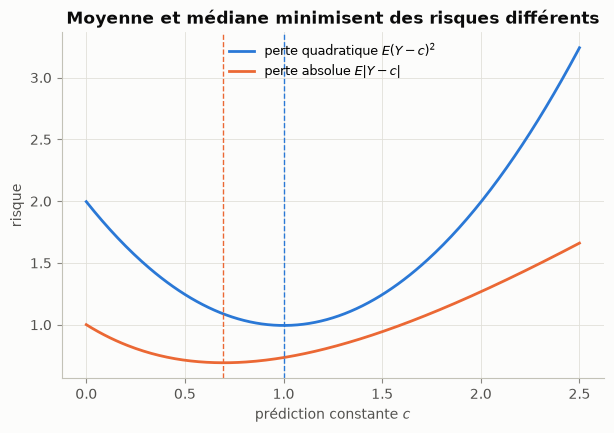

argmin quadratique : 1.000 (moyenne 1)
argmin absolue     : 0.700 (médiane ln 2 = 0.693)


In [4]:
y_s = rng.exponential(size=100000)
cs = np.linspace(0, 2.5, 251)
risk2 = np.array([np.mean((y_s - c) ** 2) for c in cs])
risk1 = np.array([np.mean(np.abs(y_s - c)) for c in cs])
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(cs, risk2, color=BLUE, label="perte quadratique $E(Y-c)^2$")
ax.plot(cs, risk1, color=ORANGE, label="perte absolue $E|Y-c|$")
ax.axvline(1.0, color=BLUE, ls="--", lw=1)
ax.axvline(np.log(2), color=ORANGE, ls="--", lw=1)
ax.set_xlabel("prédiction constante $c$")
ax.set_ylabel("risque")
ax.set_title("Moyenne et médiane minimisent des risques différents")
ax.legend()
plt.show()
print("argmin quadratique : %.3f (moyenne 1)" % cs[risk2.argmin()])
print("argmin absolue     : %.3f (médiane ln 2 = %.3f)" % (cs[risk1.argmin()], np.log(2)))

La médiane est plus **robuste** aux valeurs extrêmes que la moyenne, mais la perte
absolue n'est pas dérivable en 0, ce qui complique les calculs. La perte quadratique
reste la plus utilisée (on verra au chapitre 10 d'autres pertes robustes).

## 4. Sortie qualitative : la perte 0-1 et le classifieur de Bayes

Si la sortie $G$ prend ses valeurs dans $\mathcal G = \{\mathcal G_1, \dots, \mathcal G_K\}$,
la perte est décrite par une **matrice** $\mathbf L$ de taille $K\times K$, où
$L(k, \ell)$ est le coût d'une observation de classe $\mathcal G_k$ classée en
$\mathcal G_\ell$ (avec $L(k,k) = 0$). L'erreur de prédiction espérée est
$$\mathrm{EPE} = E\big[L(G, \hat G(X))\big] \qquad \text{(éq. (2.19))}.$$

En conditionnant par $X$ (comme plus haut) :
$$\mathrm{EPE} = E_X\Big[\sum_{k=1}^K L(\mathcal G_k, \hat G(X))\,\Pr(\mathcal G_k \mid X)\Big] \qquad \text{(éq. (2.20))},$$
et il suffit de minimiser point par point :
$$\hat G(x) = \arg\min_{g\in\mathcal G}\sum_{k=1}^K L(\mathcal G_k, g)\Pr(\mathcal G_k\mid X = x) \qquad \text{(éq. (2.21))}.$$

Avec la **perte 0-1** (tous les mauvais classements coûtent 1), la somme vaut
$\sum_{k : \mathcal G_k \ne g}\Pr(\mathcal G_k \mid x) = 1 - \Pr(g \mid X = x)$. Minimiser
revient donc à **maximiser** $\Pr(g \mid X = x)$ :
$$\hat G(x) = \mathcal G_k \quad\text{si}\quad \Pr(\mathcal G_k \mid X = x) = \max_{g\in\mathcal G}\Pr(g \mid X = x) \qquad \text{(éq. (2.22)-(2.23))}.$$
C'est le **classifieur de Bayes** ; son erreur est le **taux d'erreur de Bayes**.

Pour la simulation mixture (deux classes, probabilités a priori $1/2$, densités $p_0$, $p_1$),
la probabilité d'erreur de Bayes vaut
$$\Pr(\text{erreur}) = E_X\big[1 - \max_g \Pr(g\mid X)\big] = \int \min\big(\tfrac12 p_0(x), \tfrac12 p_1(x)\big)\,dx,$$
car la densité de $X$ est $\frac12(p_0 + p_1)$ et $\frac12(p_0+p_1)\,(1 - \max_g\Pr(g\mid x)) = \min(\frac12 p_0, \frac12 p_1)$.
Calculons cette intégrale par la méthode des rectangles sur une grande grille.

In [5]:
mix = datasets.load_mixture_example()
means = mix["means"]
h = 0.02
u = np.arange(-4, 6, h)
v = np.arange(-4, 6, h)
U, V = np.meshgrid(u, v)
P = np.c_[U.ravel(), V.ravel()]
p0 = c2.mixture_density(P, means[:10])
p1 = c2.mixture_density(P, means[10:])
print("masse totale (doit valoir 1) : %.5f" % ((0.5 * (p0 + p1)).sum() * h * h))
print("erreur de Bayes (intégrale)  : %.4f" % (np.minimum(p0, p1).sum() * 0.5 * h * h))

masse totale (doit valoir 1) : 1.00000
erreur de Bayes (intégrale)  : 0.2076


On retrouve l'erreur d'environ 21 % estimée par simulation au cours 1.

**Lien avec les $k$-ppv et la régression d'indicatrices.** Les $k$-ppv estiment
$\Pr(g \mid X = x)$ par la proportion de voisins de classe $g$ : c'est une approximation
directe du classifieur de Bayes. La régression d'une variable indicatrice $Y \in \{0,1\}$
estime $E(Y \mid X = x) = \Pr(G = 1 \mid X = x)$, ce qui justifie la règle (2.7).
Comparons visuellement la probabilité a posteriori exacte et son estimation par 15-ppv.

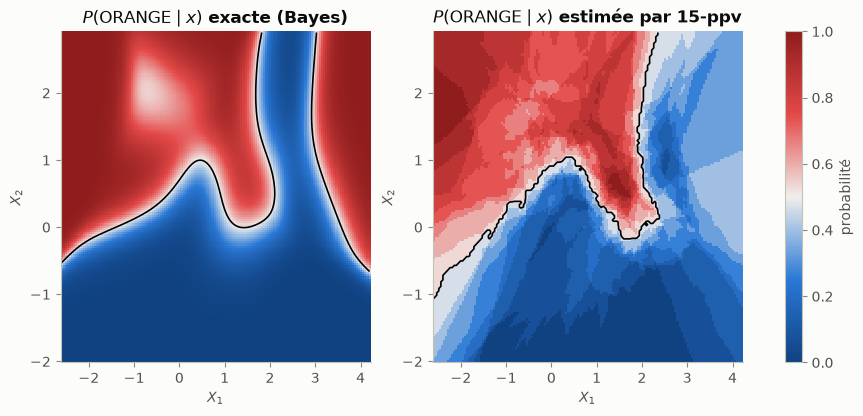

In [6]:
X, g = mix["x"], mix["y"]
xx, yy, grid = decision_grid((-2.6, 4.2), (-2.0, 2.9), n=150)
post = c2.bayes_posterior(grid, means).reshape(xx.shape)
post_knn = c2.knn_regress(X, g, grid, 15).reshape(xx.shape)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
for ax, Z, name in zip(axes, [post, post_knn], ["exacte (Bayes)", "estimée par 15-ppv"]):
    im = ax.pcolormesh(xx, yy, Z, cmap=DIV, vmin=0, vmax=1, shading="auto")
    ax.contour(xx, yy, Z, levels=[0.5], colors="k", linewidths=1.2)
    ax.set_title("$P(\\mathrm{ORANGE}\\mid x)$ %s" % name)
    ax.set_xlabel("$X_1$")
    ax.set_ylabel("$X_2$")
    ax.grid(False)
fig.colorbar(im, ax=axes, label="probabilité")
plt.show()

## 5. Le fléau de la dimension (section 2.5)

Avec beaucoup de données, on pourrait croire qu'il suffit de moyenner les observations
d'un petit voisinage de $x$ pour approcher $E(Y \mid X = x)$. Cette intuition
s'effondre en grande dimension : c'est le **fléau de la dimension** (Bellman, 1961).
En voici plusieurs manifestations.

### 5.1 Les voisinages ne sont plus locaux (figure 2.6)

Soit des entrées uniformes dans le cube unité $[0,1]^p$. Un sous-cube de côté $e$ a pour
volume $e^p$ ; pour capturer une fraction $r$ des observations, il faut $e^p = r$, soit
$$e_p(r) = r^{1/p}.$$
En dimension 10 : $e_{10}(0{,}01) \approx 0{,}63$ et $e_{10}(0{,}1) \approx 0{,}80$.
Pour moyenner 1 % des données, il faut couvrir 63 % de l'étendue de **chaque** variable !

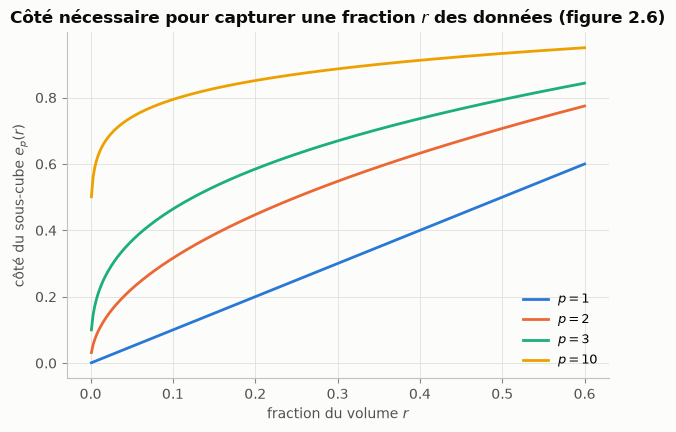

e_10(0.01) = 0.63, e_10(0.1) = 0.79


In [7]:
r = np.linspace(0.001, 0.6, 300)
fig, ax = plt.subplots(figsize=(7, 4.5))
for j, p in enumerate([1, 2, 3, 10]):
    ax.plot(r, c2.edge_length(r, p), color=COLORS[j], label="$p = %d$" % p)
ax.set_xlabel("fraction du volume $r$")
ax.set_ylabel("côté du sous-cube $e_p(r)$")
ax.set_title("Côté nécessaire pour capturer une fraction $r$ des données (figure 2.6)")
ax.legend()
plt.show()
print("e_10(0.01) = %.2f, e_10(0.1) = %.2f" % (c2.edge_length(0.01, 10), c2.edge_length(0.1, 10)))

### 5.2 Tous les points sont près du bord

Soit $N$ points uniformes dans la boule unité de $\mathbb R^p$, et le point cible à
l'origine. La **distance médiane** de l'origine au point le plus proche vaut
(exercice 2.3) :
$$d(p, N) = \Big(1 - \big(\tfrac12\big)^{1/N}\Big)^{1/p} \qquad \text{(éq. (2.24))}.$$
Pour $N = 500$ et $p = 10$, $d \approx 0{,}52$ : le plus proche voisin est plus près du
bord que du centre. Vérifions par simulation.

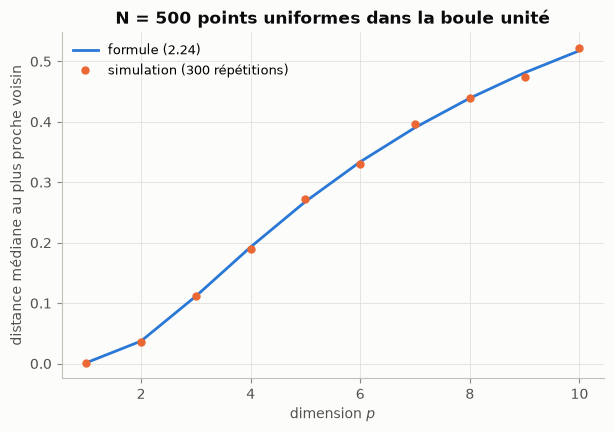

d(10, 500) = 0.518


In [8]:
N = 500
ps = np.arange(1, 11)
d_sim = []
for p in ps:
    d = [np.linalg.norm(c2.sample_unit_ball(N, p, rng), axis=1).min() for _ in range(300)]
    d_sim.append(np.median(d))
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(ps, c2.median_nn_distance(ps, N), color=BLUE, label="formule (2.24)")
ax.plot(ps, d_sim, "o", color=ORANGE, label="simulation (300 répétitions)")
ax.set_xlabel("dimension $p$")
ax.set_ylabel("distance médiane au plus proche voisin")
ax.set_title("N = 500 points uniformes dans la boule unité")
ax.legend()
plt.show()
print("d(10, 500) = %.3f" % c2.median_nn_distance(10, 500))

Pourquoi est-ce gênant ? Près du bord de l'échantillon, on doit **extrapoler** à partir
de voisins tous situés du même côté, au lieu d'**interpoler** entre eux : la prédiction
est beaucoup plus difficile.

### 5.3 La densité d'échantillonnage

La densité d'échantillonnage est proportionnelle à $N^{1/p}$ : si $N_1 = 100$ points
forment un échantillon dense en dimension 1, il en faut $N_{10} = 100^{10} = 10^{20}$
pour la même densité en dimension 10. En grande dimension, tout échantillon réaliste
est **clairsemé**.

### 5.4 Biais et variance du 1-ppv en dimension croissante (figure 2.7)

Prenons $N = 1000$ points $x_i$ uniformes sur $[-1, 1]^p$ et la relation **déterministe**
$$Y = f(X) = e^{-8\|X\|^2}.$$
On prédit $f(0) = 1$ par le 1-ppv : $\hat y_0 = f(x_{(1)})$, où $x_{(1)}$ est le point
d'apprentissage le plus proche de $x_0 = 0$.

En moyennant sur les échantillons d'apprentissage $\mathcal T$, l'erreur quadratique
moyenne se décompose (on ajoute et retranche $E_{\mathcal T}\hat y_0$ ; le double produit
est d'espérance nulle) :
$$\begin{aligned}
\mathrm{MSE}(x_0) &= E_{\mathcal T}\big[f(x_0) - \hat y_0\big]^2\\
&= E_{\mathcal T}\big[\hat y_0 - E_{\mathcal T}(\hat y_0)\big]^2 + \big[E_{\mathcal T}(\hat y_0) - f(x_0)\big]^2\\
&= \mathrm{Var}_{\mathcal T}(\hat y_0) + \mathrm{Biais}^2(\hat y_0) \qquad \text{(éq. (2.25))}.
\end{aligned}$$
C'est la **décomposition biais-variance**.

Pour simuler efficacement, remarquons que seule la **distance** $\|x_{(1)}\|$ du plus
proche voisin à l'origine compte, puisque $f$ ne dépend que de $\|x\|$.

In [9]:
def nn_to_origin(N, p, reps, rng, chunk=100):
    """Points d'apprentissage les plus proches de l'origine, pour `reps` échantillons."""
    out = np.empty((reps, p))
    for s in range(0, reps, chunk):
        Xs = rng.uniform(-1, 1, size=(min(chunk, reps - s), N, p))
        idx = np.argmin((Xs ** 2).sum(axis=2), axis=1)
        out[s:s + len(idx)] = Xs[np.arange(len(idx)), idx]
    return out


reps = 1000
res = {"dist": [], "mse": [], "var": [], "bias2": []}
nn_points = {}
for p in ps:
    xn = nn_to_origin(1000, p, reps, rng)
    nn_points[p] = xn
    y0 = np.exp(-8 * (xn ** 2).sum(1))
    res["dist"].append(np.linalg.norm(xn, axis=1).mean())
    res["mse"].append(np.mean((1 - y0) ** 2))
    res["var"].append(y0.var())
    res["bias2"].append((y0.mean() - 1) ** 2)

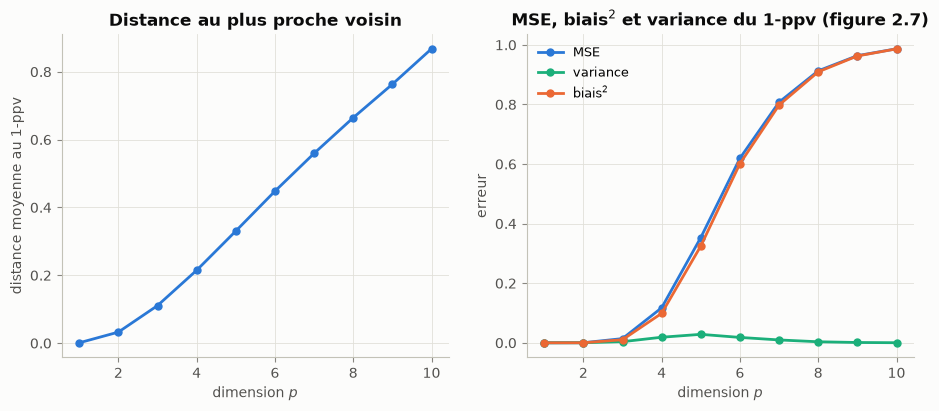

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].plot(ps, res["dist"], "o-", color=BLUE)
axes[0].set_xlabel("dimension $p$")
axes[0].set_ylabel("distance moyenne au 1-ppv")
axes[0].set_title("Distance au plus proche voisin")
for key, col, name in [("mse", COLORS[0], "MSE"), ("var", COLORS[2], "variance"),
                       ("bias2", COLORS[1], "biais$^2$")]:
    axes[1].plot(ps, res[key], "o-", color=col, label=name)
axes[1].set_xlabel("dimension $p$")
axes[1].set_ylabel("erreur")
axes[1].set_title("MSE, biais$^2$ et variance du 1-ppv (figure 2.7)")
axes[1].legend()
plt.show()

En petite dimension, le plus proche voisin est très proche de 0, et biais comme variance
sont faibles. Quand $p$ augmente, il s'éloigne : $\hat y_0 = e^{-8\|x_{(1)}\|^2}$ tend vers 0,
le **biais** domine et le MSE plafonne à 1 ; la variance finit même par diminuer
(artefact de cet exemple, où $\hat y_0$ est presque toujours $\approx 0$).

In [11]:
p10 = np.linalg.norm(nn_points[10], axis=1)
print("p = 10 : proportion des échantillons où le 1-ppv est à distance > 0.5 : %.3f"
      % np.mean(p10 > 0.5))

p = 10 : proportion des échantillons où le 1-ppv est à distance > 0.5 : 0.997


### 5.5 Quand c'est la variance qui domine (figure 2.8)

Le comportement dépend de la vraie fonction. Avec la même configuration mais
$f(X) = \frac12(X_1 + 1)^3$, qui ne dépend que de la **première** coordonnée, le biais
reste faible (seul l'écart selon $X_1$ compte) et c'est la **variance** qui domine.

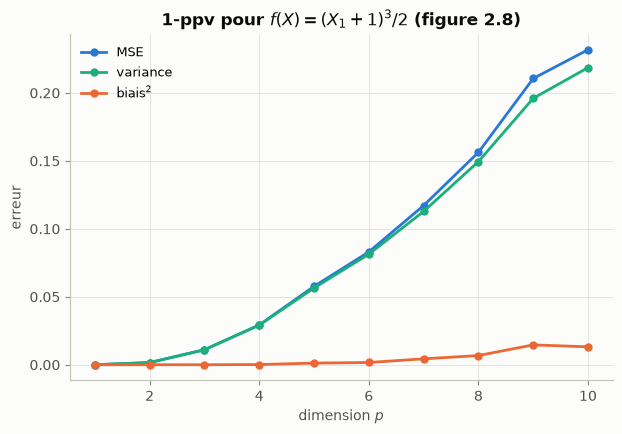

In [12]:
res3 = {"mse": [], "var": [], "bias2": []}
for p in ps:
    y0 = 0.5 * (nn_points[p][:, 0] + 1) ** 3
    res3["mse"].append(np.mean((0.5 - y0) ** 2))
    res3["var"].append(y0.var())
    res3["bias2"].append((y0.mean() - 0.5) ** 2)

fig, ax = plt.subplots(figsize=(7, 4.5))
for key, col, name in [("mse", COLORS[0], "MSE"), ("var", COLORS[2], "variance"),
                       ("bias2", COLORS[1], "biais$^2$")]:
    ax.plot(ps, res3[key], "o-", color=col, label=name)
ax.set_xlabel("dimension $p$")
ax.set_ylabel("erreur")
ax.set_title("1-ppv pour $f(X) = (X_1+1)^3/2$ (figure 2.8)")
ax.legend()
plt.show()

### 5.6 Le modèle linéaire échappe au fléau, s'il est correct

Supposons maintenant $Y = X^T\beta + \varepsilon$ avec $\varepsilon \sim \mathcal N(0,\sigma^2)$
(éq. (2.26)), ajusté par moindres carrés. L'exercice 2.5 établit
$$\mathrm{EPE}(x_0) = \sigma^2 + E_{\mathcal T}\big[x_0^T(\mathbf X^T\mathbf X)^{-1}x_0\big]\sigma^2 + 0^2 \qquad \text{(éq. (2.27))}$$
(pas de biais : les moindres carrés sont sans biais sous ce modèle), puis, pour $N$
grand et $E(X) = 0$,
$$E_{x_0}\mathrm{EPE}(x_0) \approx \sigma^2\,\frac pN + \sigma^2 \qquad \text{(éq. (2.28))}.$$
L'EPE croît **linéairement** en $p$, avec une pente $\sigma^2/N$ minuscule si $N$ est
grand : la structure imposée au modèle évite le fléau.

In [13]:
N, sigma = 200, 1.0
p_list = np.arange(1, 41, 3)
epe = []
for p in p_list:
    errs = []
    for _ in range(300):
        Xtr = rng.normal(size=(N, p))
        beta_true = np.ones(p)
        ytr = Xtr @ beta_true + sigma * rng.normal(size=N)
        bh = c2.least_squares_fit(Xtr, ytr, intercept=False)
        x0 = rng.normal(size=(50, p))
        y0 = x0 @ beta_true + sigma * rng.normal(size=50)
        errs.append(np.mean((y0 - x0 @ bh) ** 2))
    epe.append(np.mean(errs))